In [3]:
import sys
import matplotlib
import numpy as np
import pandas as pd
import sklearn

# Печатаем версии среды и основных библиотек одним блоком.
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.3
Pandas: 3.0.6
Matplotlib: 3.11.2
scikit-learn: 1.9.1


In [4]:
# Скрываем только предупреждения о будущих изменениях API;
# остальные предупреждения оставляем видимыми.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Базовые библиотеки для вычислений, таблиц и графиков.
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Компоненты scikit-learn сгруппированы по назначению.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Все случайные операции используют одно значение для воспроизводимости.
RANDOM_STATE = 4            # только для учебного примера
TEST_SIZE = 0.20
SCORING = "f1_macro"


Источник: локальная копия ML_Lab1_Datasets\variant_04.csv
Размер X: (2000, 65)
Классы: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,att1,att2,att3,att4,att5,att6,att7,att8,att9,att10,...,att56,att57,att58,att59,att60,att61,att62,att63,att64,class
0,-10.297008,-11.666789,11.560669,-2.081316,4.044656,4.086815,-2.558072,-8.476935,2.138135,3.503082,...,0.921927,0.496387,-0.643667,0.284104,0.286555,0.348625,1.814691,-1.351353,-0.473910,1
1,-5.036009,-12.885333,0.161155,0.592460,3.123534,4.220469,-6.411771,-6.335328,-0.244622,1.346073,...,2.938791,1.429883,-2.336344,1.281628,-0.098321,0.582357,0.485792,0.642451,0.613107,1
2,-9.639157,-6.655898,0.388687,-1.717650,0.300346,3.400769,-7.240785,-1.659405,-0.874005,4.153403,...,-0.023028,-0.025265,1.259838,-0.441360,-0.960094,1.995843,1.097748,0.827182,-1.767840,1
3,-6.650375,-7.043851,4.104350,-2.342780,3.494658,3.924822,-9.874812,-6.556576,-1.364269,1.153308,...,-1.043815,-0.204508,-1.981150,0.982438,-0.144233,-1.449328,-0.913552,-0.771735,0.304992,1
4,-10.664524,-10.974133,0.194391,0.453885,2.193088,-3.304663,-8.376592,-4.241146,2.964818,-0.949622,...,1.448160,-1.254907,-3.481295,-0.563889,1.529335,0.510399,0.298318,-0.943213,1.149847,1


,dtype,n_unique,n_missing,missing_share
att1,float64,1994,0,0.0
att2,float64,1994,0,0.0
att3,float64,1994,0,0.0
att4,float64,1994,0,0.0
att5,float64,1994,0,0.0
...,...,...,...,...
att61,float64,1994,0,0.0
att62,float64,1994,0,0.0
att63,float64,1993,0,0.0
att64,float64,1994,0,0.0


,count,share
class,,
1,200,0.1
2,200,0.1
3,200,0.1
4,200,0.1
5,200,0.1
6,200,0.1
7,200,0.1
8,200,0.1
9,200,0.1


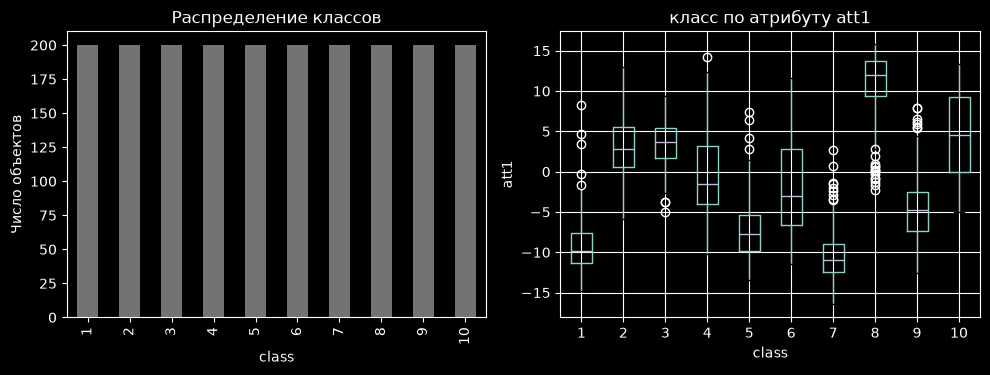

In [5]:
from IPython.display import display
from pathlib import Path

# Сначала пытаемся использовать приложенную локальную копию.
example_path = Path("ML_Lab1_Datasets") / "variant_04.csv"

if example_path.exists():
    frame = pd.read_csv(example_path)
    print("Источник: локальная копия", example_path)
else:
    # Резервный вариант нужен, если архив с данными не был распакован.
    data = fetch_openml(data_id=16, as_frame=True)
    frame = data.data.copy()
    frame["class"] = data.target
    print("Источник: OpenML, data_id 16")

X = frame.copy()
y = pd.to_numeric(frame["class"]).astype("int64")

# Проверяем размерность, классы и первые строки до дальнейшей обработки.
print("Размер X:", X.shape)
print("Классы:", sorted(y.unique()))
display(X.head())

# Карточка признаков объединяет тип, число значений и статистику пропусков.
data_card = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "n_unique": X.nunique(dropna=True),
    "n_missing": X.isna().sum(),
    "missing_share": X.isna().mean().round(3),
})

# Отдельно оцениваем абсолютный и относительный размер каждого класса.
class_table = pd.DataFrame({
    "count": y.value_counts().sort_index(),
    "share": y.value_counts(normalize=True).sort_index().round(3),
})

# display удобнее print для просмотра таблиц внутри Jupyter Notebook.
display(data_card)
display(class_table)

# На одном рисунке показываем баланс классов и распределение возраста.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Столбчатая диаграмма позволяет быстро увидеть дисбаланс классов.
y.value_counts().sort_index().plot.bar(ax=axes[0], color="0.45")
axes[0].set_title("Распределение классов")
axes[0].set_xlabel("class")
axes[0].set_ylabel("Число объектов")

plot_frame = pd.DataFrame({"att1": X["att1"], "class": y})
# Boxplot показывает медиану, разброс и возможные выбросы по каждому классу.
plot_frame.boxplot(column="att1", by="class", ax=axes[1])
axes[1].set_title("класс по атрибуту att1")
axes[1].set_xlabel("class")
axes[1].set_ylabel("att1")

# Pandas добавляет общий заголовок автоматически — убираем его перед выводом.
plt.suptitle("")
plt.tight_layout()
plt.show()


In [4]:
#Далее идёт уже ML
## 5. Разбиение данных

In [6]:
# Тестовая выборка отделяется один раз и остаётся закрытой до финальной оценки.
# stratify сохраняет приблизительные доли классов в обеих частях.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

# Кросс-валидация применяется только внутри обучающей части.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("CV:", cv)

# Размерности помогают проверить, что разбиение выполнено ожидаемым образом.
print("Train:", X_train.shape)
print("Test:", X_test.shape)




CV: StratifiedKFold(n_splits=5, random_state=4, shuffle=True)
Train: (1600, 65)
Test: (400, 65)


In [7]:
## 6. Базовая модель
# most_frequent всегда предсказывает самый частый класс и не использует признаки.
baseline = DummyClassifier(strategy="most_frequent")

# Используем ту же CV-схему, что и для основных моделей.
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
)

print(baseline_cv)

# Усредняем метрики по пяти фолдам для компактного сравнения.
baseline_summary = pd.Series({
    "accuracy_cv_mean": baseline_cv["test_accuracy"].mean(),
    "f1_macro_cv_mean": baseline_cv["test_f1_macro"].mean(),
})
display(baseline_summary.round(4))

{'fit_time': array([0.0037508 , 0.00181007, 0.00181079, 0.00173926, 0.00169635]), 'score_time': array([0.00607038, 0.00632834, 0.00492978, 0.00444174, 0.00516176]), 'test_accuracy': array([0.1, 0.1, 0.1, 0.1, 0.1]), 'test_f1_macro': array([0.01818182, 0.01818182, 0.01818182, 0.01818182, 0.01818182])}


accuracy_cv_mean    0.1000
f1_macro_cv_mean    0.0182
dtype: float64

In [15]:
## 7. Подготовка данных для ручной реализации SGD

manual_features = X.axes[1][:-1]

X_demo_train, X_demo_val, y_demo_train, y_demo_val = train_test_split(
    X_train[manual_features],
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_demo_train = imputer.fit_transform(X_demo_train)
X_demo_val = imputer.transform(X_demo_val)

X_demo_train = scaler.fit_transform(X_demo_train)
X_demo_val = scaler.transform(X_demo_val)

y_demo_train_pm = np.where(y_demo_train.to_numpy() == 1, 1.0, -1.0)
y_demo_val_pm = np.where(y_demo_val.to_numpy() == 1, 1.0, -1.0)

In [16]:
## 8. Функции потерь и обучения

def sigmoid(z):
    z = np.clip(np.asarray(z, dtype=float), -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z))


def mean_logistic_loss(X, y_pm, w, b):
    margins = y_pm * (X @ w + b)
    return np.mean(np.logaddexp(0.0, -margins))


def train_logreg_sgd(
    X_train, y_train_pm, X_val, y_val_pm, *,
    eta=0.01, tau=1e-4, epochs=50, random_state=42,
):
    rng = np.random.default_rng(random_state)
    w = np.zeros(X_train.shape[1], dtype=float)
    b = 0.0
    history = {"train_loss": [], "val_loss": [], "weight_norm": []}

    for _ in range(epochs):
        for i in rng.permutation(len(X_train)):
            x_i = X_train[i]
            y_i = y_train_pm[i]
            margin = y_i * (x_i @ w + b)

            factor = -y_i * sigmoid(-margin)
            grad_w = factor * x_i + tau * w
            grad_b = factor

            w -= eta * grad_w
            b -= eta * grad_b

        history["train_loss"].append(mean_logistic_loss(X_train, y_train_pm, w, b))
        history["val_loss"].append(mean_logistic_loss(X_val, y_val_pm, w, b))
        history["weight_norm"].append(np.linalg.norm(w))

    return w, b, pd.DataFrame(history)

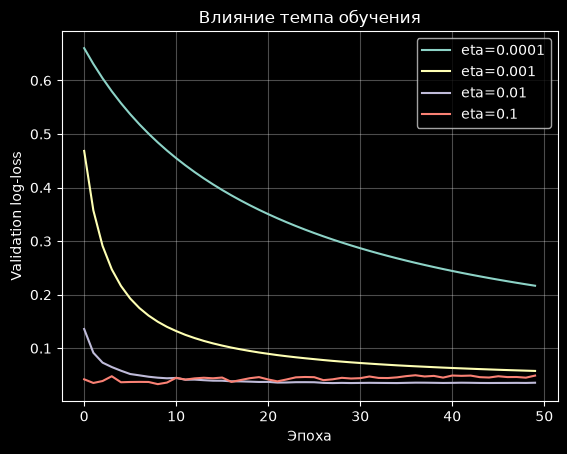

,final_train_loss,final_val_loss,weight_norm
0.0001,0.2093,0.2167,0.8067
0.0010,0.0458,0.0576,2.1937
0.0100,0.0118,0.0356,4.3871
0.1000,0.0027,0.0489,7.7139


In [17]:
## 9. Исследование темпа обучения
eta_values = [0.0001, 0.001, 0.01, 0.1]
eta_runs = {}

for eta in eta_values:
    _, _, history = train_logreg_sgd(
        X_demo_train, y_demo_train_pm,
        X_demo_val, y_demo_val_pm,
        eta=eta, tau=1e-4, epochs=50,
        random_state=RANDOM_STATE,
    )
    eta_runs[eta] = history
    plt.plot(history["val_loss"], label=f"eta={eta}")

plt.xlabel("Эпоха")
plt.ylabel("Validation log-loss")
plt.title("Влияние темпа обучения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

eta_result = pd.DataFrame({
    eta: {
        "final_train_loss": h["train_loss"].iloc[-1],
        "final_val_loss": h["val_loss"].iloc[-1],
        "weight_norm": h["weight_norm"].iloc[-1],
    }
    for eta, h in eta_runs.items()
}).T
display(eta_result.round(4))

In [18]:
## 10. Исследование регуляризации
best_eta = eta_result["final_val_loss"].idxmin()
tau_values = [0.0, 1e-4, 1e-2]
tau_result = []

for tau in tau_values:
    w_sgd, b_sgd, history = train_logreg_sgd(
        X_demo_train, y_demo_train_pm,
        X_demo_val, y_demo_val_pm,
        eta=float(best_eta), tau=tau, epochs=50,
        random_state=RANDOM_STATE,
    )
    tau_result.append({
        "tau": tau,
        "val_loss": history["val_loss"].iloc[-1],
        "weight_norm": np.linalg.norm(w_sgd),
    })

tau_result = pd.DataFrame(tau_result)
display(tau_result.round(4))

,tau,val_loss,weight_norm
0,0.0000,0.0357,4.4544
1,0.0001,0.0356,4.3871
2,0.0100,0.0488,2.3925


In [19]:
## 11. Полный preprocessing pipeline
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

sgd_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", SGDClassifier(
        loss="log_loss",
        penalty="l2",
        learning_rate="constant",
        max_iter=2000,
        tol=1e-4,
        random_state=RANDOM_STATE,
    )),
])

In [20]:
## 12. Подбор гиперпараметров SGD
sgd_param_grid = {
    "model__eta0": [0.001, 0.01, 0.1],
    "model__alpha": [1e-6, 1e-4, 1e-2],
}

sgd_search = GridSearchCV(
    estimator=sgd_pipeline,
    param_grid=sgd_param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
sgd_search.fit(X_train, y_train)

print("Лучшие параметры SGD:", sgd_search.best_params_)
print("Лучший CV macro-F1:", round(sgd_search.best_score_, 4))

sgd_cv_table = pd.DataFrame(sgd_search.cv_results_)[[
    "param_model__eta0",
    "param_model__alpha",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].sort_values("rank_test_score")
display(sgd_cv_table.round(4))

Лучшие параметры SGD: {'model__alpha': 0.01, 'model__eta0': 0.01}
Лучший CV macro-F1: 0.9611


,param_model__eta0,param_model__alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
7,0.010,0.0100,0.9833,0.9611,0.0153,1
6,0.001,0.0100,0.9803,0.9599,0.0147,2
3,0.001,0.0001,0.9889,0.9592,0.0150,3
0,0.001,0.0000,0.9891,0.9592,0.0150,4
4,0.010,0.0001,0.9992,0.9586,0.0132,5
1,0.010,0.0000,0.9992,0.9586,0.0132,5
2,0.100,0.0000,0.9986,0.9549,0.0135,7
5,0.100,0.0001,0.9966,0.9548,0.0124,8
8,0.100,0.0100,0.9675,0.9422,0.0107,9


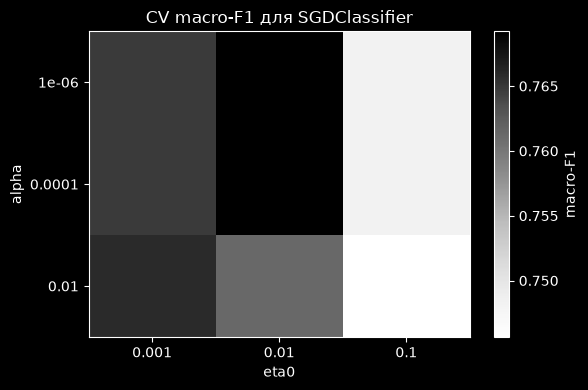

In [16]:
## 13. Тепловая карта CV
pivot = sgd_cv_table.pivot_table(
    index="param_model__alpha",
    columns="param_model__eta0",
    values="mean_test_score",
)

fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(pivot.to_numpy(), cmap="Greys", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), labels=pivot.columns)
ax.set_yticks(range(len(pivot.index)), labels=pivot.index)
ax.set_xlabel("eta0")
ax.set_ylabel("alpha")
ax.set_title("CV macro-F1 для SGDClassifier")
fig.colorbar(image, ax=ax, label="macro-F1")
plt.tight_layout()
plt.show()

In [21]:
## 14. Подбор C для LogisticRegression
logreg_pipeline = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE,
    )),
])

logreg_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0]},
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
)
logreg_search.fit(X_train, y_train)

cv_comparison = pd.DataFrame([
    {
        "model": "DummyClassifier",
        "best_params": "strategy=most_frequent",
        "cv_macro_f1": baseline_summary["f1_macro_cv_mean"],
    },
    {
        "model": "SGDClassifier",
        "best_params": str(sgd_search.best_params_),
        "cv_macro_f1": sgd_search.best_score_,
    },
    {
        "model": "LogisticRegression",
        "best_params": str(logreg_search.best_params_),
        "cv_macro_f1": logreg_search.best_score_,
    },
]).sort_values("cv_macro_f1", ascending=False)

display(cv_comparison.round(4))

candidate_comparison = cv_comparison[
    cv_comparison["model"] != "DummyClassifier"
].reset_index(drop=True)

,model,best_params,cv_macro_f1
1,SGDClassifier,"{'model__alpha': 0.01, 'model__eta0': 0.01}",0.9611
2,LogisticRegression,{'model__C': 0.1},0.9611
0,DummyClassifier,strategy=most_frequent,0.0182


In [22]:
## 15. Финальная оценка на test
def evaluate_classifier(name, estimator, X_eval, y_eval):
    prediction = estimator.predict(X_eval)
    probabilities = estimator.predict_proba(X_eval)
    classes = estimator.classes_

    if len(classes) == 2:
        positive_class = classes[1]
        y_binary = (np.asarray(y_eval) == positive_class).astype(int)
        auc = roc_auc_score(y_binary, probabilities[:, 1])
    else:
        auc = roc_auc_score(
            y_eval, probabilities, labels=classes,
            multi_class="ovr", average="macro",
        )

    return {
        "model": name,
        "accuracy": accuracy_score(y_eval, prediction),
        "precision_macro": precision_score(y_eval, prediction, average="macro", zero_division=0),
        "recall_macro": recall_score(y_eval, prediction, average="macro", zero_division=0),
        "f1_macro": f1_score(y_eval, prediction, average="macro", zero_division=0),
        "roc_auc": auc,
    }

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,DummyClassifier,0.1000,0.0100,0.1000,0.0182,0.5000
1,SGDClassifier,0.9650,0.9658,0.9650,0.9650,0.9938
2,LogisticRegression,0.9725,0.9733,0.9725,0.9726,0.9963


              precision    recall  f1-score   support

           1       1.00      1.00      1.00        40
           2       0.95      0.95      0.95        40
           3       1.00      1.00      1.00        40
           4       0.95      0.95      0.95        40
           5       0.95      0.97      0.96        40
           6       0.95      0.90      0.92        40
           7       0.95      0.95      0.95        40
           8       1.00      0.95      0.97        40
           9       1.00      0.97      0.99        40
          10       0.91      1.00      0.95        40

    accuracy                           0.96       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.97      0.96      0.97       400



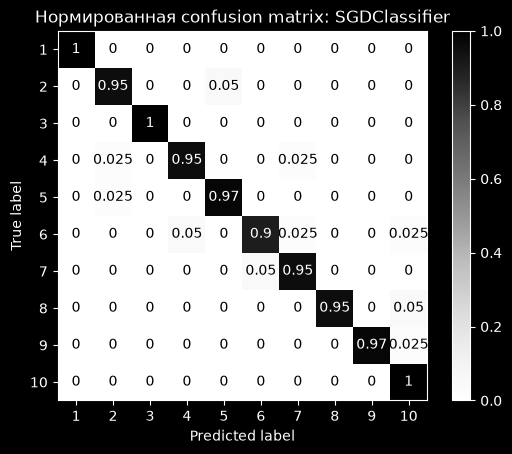

In [23]:
baseline.fit(X_train, y_train)

final_models = {
    "DummyClassifier": baseline,
    "SGDClassifier": sgd_search.best_estimator_,
    "LogisticRegression": logreg_search.best_estimator_,
}

test_results = pd.DataFrame([
    evaluate_classifier(name, model, X_test, y_test)
    for name, model in final_models.items()
])
display(test_results.round(4))

selected_name = candidate_comparison.iloc[0]["model"]
selected_model = final_models[selected_name]
selected_prediction = selected_model.predict(X_test)

print(classification_report(y_test, selected_prediction, zero_division=0))

ConfusionMatrixDisplay.from_estimator(
    selected_model, X_test, y_test,
    normalize="true", cmap="Greys",
)
plt.title(f"Нормированная confusion matrix: {selected_name}")
plt.show()

In [24]:
## 16. Анализ ошибок
error_table = X_test.copy()
error_table["true"] = np.asarray(y_test)
error_table["predicted"] = selected_prediction

selected_probabilities = selected_model.predict_proba(X_test)
error_table["confidence"] = selected_probabilities.max(axis=1)

errors = error_table[
    error_table["true"] != error_table["predicted"]
].sort_values("confidence", ascending=False)

display(errors.head(10))

,att1,att2,att3,att4,att5,att6,att7,att8,att9,att10,...,att59,att60,att61,att62,att63,att64,class,true,predicted,confidence
1437,0.682751,-14.166030,4.710316,3.088776,3.920460,1.714521,0.345176,-1.737781,-1.200892,-0.479401,...,0.405246,0.466078,0.728205,0.941327,1.242569,0.176198,8,8,10,0.775896
649,5.363024,5.736277,2.384048,9.232138,5.200172,2.759709,-1.706314,-5.239243,-0.998453,-4.865503,...,-0.491188,0.309731,0.251703,-0.952100,0.045706,1.064896,4,4,2,0.731914
1175,6.009644,5.326163,-6.855350,-4.790557,-0.608771,-1.465028,0.641770,-1.866079,2.562773,-3.733131,...,-0.786464,-0.212199,-0.439084,0.205497,-1.721534,-0.985558,6,6,7,0.703259
1145,-4.551072,-1.730288,-0.523709,6.735461,7.163551,-1.385373,-2.470841,-0.408556,2.510832,-0.462439,...,-1.258952,-0.310946,0.533179,-0.222712,1.667020,-0.450128,6,6,10,0.681502
1352,-8.470568,0.176684,2.507809,-1.625078,7.441055,-0.517329,-4.689508,-4.595439,-2.561024,-5.905316,...,-0.177336,0.169032,1.276661,0.971415,0.561234,-0.570996,7,7,6,0.642330
1696,-3.009958,4.718588,-3.151497,0.659882,5.039562,1.686151,10.997930,0.208126,-4.521344,-5.630560,...,-1.429585,-0.739495,-1.015921,0.100900,2.050729,-0.518412,9,9,10,0.639602
1141,8.520839,-4.114914,-1.913378,5.044982,-2.672985,-1.970719,-7.132088,2.457937,0.990540,-0.137217,...,-0.644636,1.343429,-2.587622,1.769855,-0.457811,-0.637831,6,6,4,0.631339
1444,4.677450,-7.920971,3.026203,3.442073,4.367340,4.372218,0.650011,-1.942088,-4.856296,-2.489994,...,-0.102512,-0.453230,0.326818,0.755351,1.183234,0.477290,8,8,10,0.608981
219,-2.673033,5.039901,-6.296504,-4.799183,3.910658,-1.491217,6.730593,-2.760767,1.939951,-7.927518,...,-1.543747,-1.122722,-0.009701,-0.507349,1.065224,-0.155742,2,2,5,0.536031
1300,-10.478772,0.672581,-2.181400,-2.040978,5.534558,3.773640,-0.690947,-1.544184,-1.008522,-2.845793,...,-1.344934,-1.776232,-1.319196,-0.074230,-0.396122,-0.518712,7,7,6,0.499968


In [25]:
## 17. Анализ коэффициентов
feature_names = selected_model.named_steps["prep"].get_feature_names_out()
model = selected_model.named_steps["model"]

class_index = 0
coefficients = model.coef_[class_index]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(coefficients),
}).sort_values("abs_coefficient", ascending=False)

display(coefficient_table.head(15))

,feature,coefficient,abs_coefficient
64,num__class,-1.304415,1.304415
1,num__att2,-0.748689,0.748689
0,num__att1,-0.681966,0.681966
6,num__att7,-0.679161,0.679161
13,num__att14,0.456536,0.456536
3,num__att4,-0.453264,0.453264
19,num__att20,0.368249,0.368249
18,num__att19,0.349367,0.349367
25,num__att26,0.322634,0.322634
22,num__att23,0.312705,0.312705
